# 複数の時代にまたがる意味の変化を 1 つのモデルで追う (Temporal Referencing)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/18_lexical_semantics/temporal_referencing.ipynb)

NLP クックブック 18-13 ／ 語の意味と意味の変化

3 つ以上の時代にわたって、ある単語の使われ方がいつ変わったのかを見たい。時代ごとのモデルの位置合わせをせずに済ませたい。

In [1]:
!pip install -q datasets fugashi unidic-lite gensim matplotlib-fontja

In [2]:
import random, re
import numpy as np
from datasets import load_dataset
from fugashi import Tagger
from gensim.models import Word2Vec

ds = load_dataset("globis-university/aozorabunko-clean", split="train")
tagger = Tagger("-Owakati")
random.seed(0)
PERIODS = [(1850, 1870), (1870, 1885), (1885, 1895), (1895, 1905), (1905, 1930)]     # 作者の生年で 5 つに分ける
TARGETS = ["原子", "同志", "活動", "戦争", "自由", "放送", "言葉", "必要"]

def period(meta):
    year = (meta.get("生年月日") or "")[:4]
    if meta["文字遣い種別"] != "新字新仮名" or not year.isdigit():
        return None
    return next((i for i, (a, b) in enumerate(PERIODS) if a <= int(year) < b), None)

texts = [[] for _ in PERIODS]
for ex in ds:
    if period(ex["meta"]) is not None:
        texts[period(ex["meta"])].append(ex["text"])

# 対象語だけに時代の印を付ける (原子 → 原子_0, 原子_1, ...)。文脈語はそのままなので、全時代で共有される
sentences, counts = [], {}
for p, works in enumerate(texts):
    n = 0
    for text in random.sample(works, len(works)):
        for s in re.split(r"(?<=[。！？])|\n", text[:30000]):
            if len(s.strip()) >= 5:
                sentences.append([f"{w}_{p}" if w in TARGETS else w for w in tagger.parse(s.strip()).split()]); n += len(s)
        if n > 12_000_000:
            break
    counts[p] = n
print(len(sentences), "文 / 時代ごとの文字数", counts)

1457994 文 / 時代ごとの文字数 {0: 7052794, 1: 12021756, 2: 12006268, 3: 12020191, 4: 9018255}


In [3]:
wv = Word2Vec(sentences, vector_size=100, window=5, min_count=10, sg=1, epochs=3, workers=4, seed=0).wv

def similarity_matrix(word):
    """時代 × 時代の類似度行列。値が急に下がる境目が、使われ方の変わった時期"""
    keys = [f"{word}_{p}" for p in range(len(PERIODS))]
    return np.array([[wv.similarity(a, b) if a in wv and b in wv else np.nan for b in keys] for a in keys])

for w in ["原子", "同志", "言葉"]:
    print(w, "各時代での出現回数:", [int(wv.get_vecattr(f"{w}_{p}", "count")) if f"{w}_{p}" in wv else 0 for p in range(len(PERIODS))])
    print(similarity_matrix(w).round(2))

原子 各時代での出現回数: [0, 101, 21, 263, 183]
[[ nan  nan  nan  nan  nan]
 [ nan 1.   0.76 0.81 0.71]
 [ nan 0.76 1.   0.8  0.78]
 [ nan 0.81 0.8  1.   0.79]
 [ nan 0.71 0.78 0.79 1.  ]]
同志 各時代での出現回数: [86, 119, 181, 369, 227]
[[1.   0.75 0.74 0.55 0.64]
 [0.75 1.   0.82 0.65 0.72]
 [0.74 0.82 1.   0.66 0.67]
 [0.55 0.65 0.66 1.   0.68]
 [0.64 0.72 0.67 0.68 1.  ]]
言葉 各時代での出現回数: [1320, 1996, 3015, 2877, 3035]
[[1.   0.81 0.73 0.71 0.65]
 [0.81 1.   0.8  0.75 0.66]
 [0.73 0.8  1.   0.8  0.78]
 [0.71 0.75 0.8  1.   0.74]
 [0.65 0.66 0.78 0.74 1.  ]]


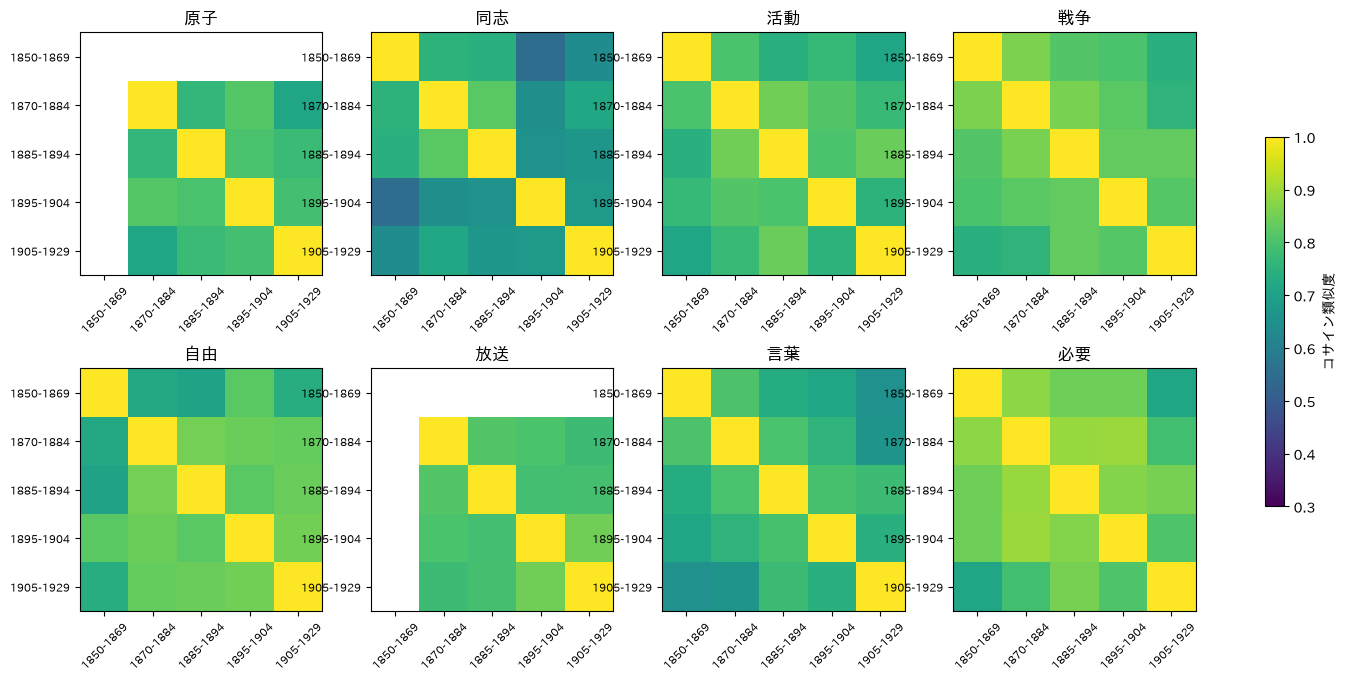

原子 (1870-1884 年生まれの作者): 機巧 放電 エントロピー 質量 電子 器官 物性
原子 (1885-1894 年生まれの作者): 余剰 エレクトロン 自爆 膠質 総量 偏差 一環
原子 (1895-1904 年生まれの作者): 磁気 力学 衛星 電子 光学 ウラニウム 変換
原子 (1905-1929 年生まれの作者): バクダン 原爆 爆弾 時限 ロケット 爆撃 ヘリウム
同志 (1850-1869 年生まれの作者): 壮士 朋友 新来 遠来 近隣 交わり 老幼
同志 (1870-1884 年生まれの作者): 同輩 古参 同業 同室 誼み 誰彼 重立っ
同志 (1885-1894 年生まれの作者): 同士 誼み 知り合っ 共々 新来 誰彼 朋友
同志 (1895-1904 年生まれの作者): 自警 党員 テロリスト 団員 連盟 モラン 闘士
同志 (1905-1929 年生まれの作者): ボル 同士 裏切り 同胞 難民 暴君 テロリスト


In [4]:
import matplotlib_fontja
import matplotlib.pyplot as plt

labels = [f"{a}-{b - 1}" for a, b in PERIODS]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, w in zip(axes.ravel(), TARGETS):
    im = ax.imshow(similarity_matrix(w), vmin=0.3, vmax=1.0, cmap="viridis")
    ax.set_xticks(range(len(labels)), labels, rotation=45, fontsize=8); ax.set_yticks(range(len(labels)), labels, fontsize=8)
    ax.set_title(w)
fig.colorbar(im, ax=axes, shrink=0.6, label="コサイン類似度")
plt.show()

# 各時代での近傍語
for w in ["原子", "同志"]:
    for p in range(len(PERIODS)):
        if f"{w}_{p}" in wv:
            near = [x for x, _ in wv.most_similar(f"{w}_{p}", topn=12) if "_" not in x][:7]
            print(f"{w} ({labels[p]} 年生まれの作者): {' '.join(near)}")

- 対象語だけを時代別の別の単語として扱い、1 つのモデルで学習する。全時代が同じベクトル空間に入るので、位置合わせによる誤差が生じない。
- 時代 × 時代の類似度行列を見ると、変化が徐々に進んだのか、ある時期を境に急に起きたのかが分かる。隣り合う時代だけを比べるより、情報が多い。
- 対象語をあらかじめ決めておく必要がある。全単語を対象にすると、時代ごとのデータが細切れになって学習できない。
- 用例の少ない時代のベクトルは不安定なので、各時代での出現回数を必ず確認する。回数が少ない時代との類似度は、意味の変化ではなく雑音かもしれない。